# Лабораторная работа № 1. Прикладная задача на табличных данных
**Дисциплина:** «Прикладные задачи искусственного интеллекта»
**Выполнил:** Клонин Н.М., гр. 23ИВ1б
**Вариант 6.** Риск отчисления студентов — набор *Predict Students' Dropout and Academic Success* (UCI, id=697).

Решение: направить студента группы риска к куратору. Пропуск студента, который отчислится, стоит C_FN = 10 усл. ед., лишняя консультация — C_FP = 1 усл. ед. Основная метрика — Macro-F1 (3 класса), порог подбирается для вероятности класса Dropout.

Ноутбук выполняется сверху вниз в Google Colab (Среда выполнения → Выполнить все).

In [1]:
!pip install -q -U scikit-learn catboost lightgbm optuna shap ucimlrepo


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\Nikita\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


## Шаг 1. Загрузка данных и постановка

In [2]:
import os, json, time, warnings, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, lightgbm as lgb, catboost, optuna, shap
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
C_FN, C_FP = 10.0, 1.0          # пропуск отчисляющегося / лишняя консультация
CLASSES = ['Dropout', 'Enrolled', 'Graduate']
os.makedirs('figures', exist_ok=True)
if os.path.exists('experiments.csv'):   # журнал пересоздаётся при полном перезапуске
    os.remove('experiments.csv')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})
print('sklearn', sklearn.__version__, '| lightgbm', lgb.__version__, '| catboost', catboost.__version__,
      '| optuna', optuna.__version__, '| shap', shap.__version__)

C:\Users\Nikita\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sklearn 1.9.1 | lightgbm 4.7.0 | catboost 1.2.10 | optuna 5.0.0 | shap 0.54.1


In [3]:
from ucimlrepo import fetch_ucirepo
ds = fetch_ucirepo(id=697)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)
df['Target'] = df['Target'].astype(str)
y_all = df['Target'].map({c: i for i, c in enumerate(CLASSES)}).astype(int)  # 0 = Dropout
print(df.shape)
df.head()

(4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


**Постановка** (подробно — в отчёте):

| Элемент | Значение |
|---|---|
| Решение и исполнитель | Учебный офис направляет студента группы риска к куратору |
| Момент прогноза | Сценарий A — зачисление; сценарий B — окончание 1-го семестра |
| Объект | Один студент (одна строка) |
| Целевая переменная | Target: Dropout / Enrolled / Graduate по окончании нормативного срока |
| Метрики | Macro-F1 (основная), ROC-AUC и Brier для вероятности Dropout |
| Цена ошибок | C_FN = 10, C_FP = 1 → t* = 1/11 ≈ 0,091 |

## Шаг 2. Разведочный анализ

In [4]:
print('Строк, столбцов:', df.shape)
print('Типы:', df.dtypes.value_counts().to_dict())
print('Пропусков всего:', int(df.isna().sum().sum()))
print('Полных дубликатов:', int(df.duplicated().sum()))
print(df['Target'].value_counts().to_frame('n').assign(share=lambda t: (t['n'] / len(df)).round(4)))

Строк, столбцов: (4424, 37)
Типы: {dtype('int64'): 29, dtype('float64'): 7, <StringDtype(storage='python', na_value=nan)>: 1}
Пропусков всего: 0
Полных дубликатов: 0
             n   share
Target                
Graduate  2209  0.4993
Dropout   1421  0.3212
Enrolled   794  0.1795


In [5]:
NOMINAL = ['Marital Status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
rare = {c: int((df[c].value_counts(normalize=True) < 0.01).sum()) for c in NOMINAL}
print('Число категорий / из них редких (<1 %):')
for c in NOMINAL:
    print(f'  {c:28s} {df[c].nunique():3d} / {rare[c]}')
num_cols = [c for c in df.columns if c not in NOMINAL + ['Target']]
df[num_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)

Число категорий / из них редких (<1 %):
  Marital Status                 6 / 3
  Application mode              18 / 9
  Course                        17 / 1
  Previous qualification        17 / 12
  Nacionality                   21 / 20
  Mother's qualification        29 / 21
  Father's qualification        34 / 27
  Mother's occupation           32 / 22
  Father's occupation           46 / 34


,mean,std,min,50%,max
Application order,1.73,1.31,0.00,1.00,9.00
Daytime/evening attendance,0.89,0.31,0.00,1.00,1.00
Previous qualification (grade),132.61,13.19,95.00,133.10,190.00
Admission grade,126.98,14.48,95.00,126.10,190.00
Displaced,0.55,0.50,0.00,1.00,1.00
Educational special needs,0.01,0.11,0.00,0.00,1.00
Debtor,0.11,0.32,0.00,0.00,1.00
Tuition fees up to date,0.88,0.32,0.00,1.00,1.00
Gender,0.35,0.48,0.00,0.00,1.00
Scholarship holder,0.25,0.43,0.00,0.00,1.00


In [6]:
# доля отчисленных по ключевым бинарным признакам
for c in ['Gender', 'Debtor', 'Tuition fees up to date', 'Scholarship holder', 'Displaced', 'International']:
    t = df.groupby(c)['Target'].apply(lambda s: (s == 'Dropout').mean()).round(3)
    print(c, t.to_dict(), '| n =', df[c].value_counts().to_dict())
print()
print(df.groupby('Target')[['Age at enrollment', 'Admission grade',
                             'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)',
                             'Curricular units 2nd sem (approved)']].median())

Gender {0: 0.251, 1: 0.451} | n = {0: 2868, 1: 1556}
Debtor {0: 0.283, 1: 0.62} | n = {0: 3921, 1: 503}
Tuition fees up to date {0: 0.866, 1: 0.247} | n = {1: 3896, 0: 528}
Scholarship holder {0: 0.387, 1: 0.122} | n = {0: 3325, 1: 1099}
Displaced {0: 0.376, 1: 0.276} | n = {1: 2426, 0: 1998}
International {0: 0.322, 1: 0.291} | n = {0: 4314, 1: 110}

          Age at enrollment  Admission grade  \
Target                                         
Dropout                23.0            123.6   
Enrolled               20.0            124.1   
Graduate               19.0            127.4   

          Curricular units 1st sem (approved)  \
Target                                          
Dropout                                   2.0   
Enrolled                                  5.0   
Graduate                                  6.0   

          Curricular units 1st sem (grade)  \
Target                                       
Dropout                          10.928571   
Enrolled             

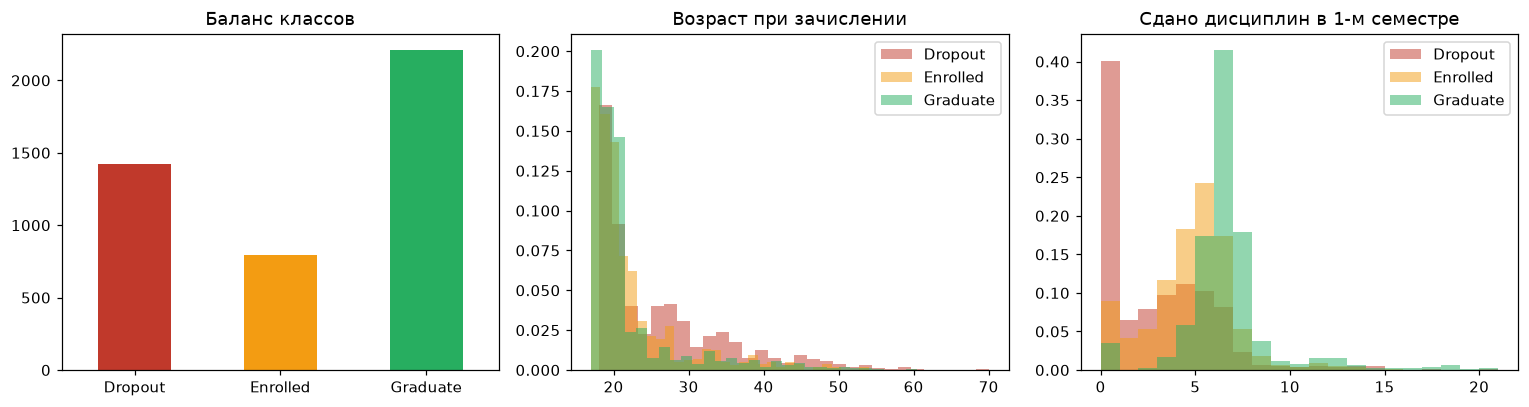

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
df['Target'].value_counts().reindex(CLASSES).plot.bar(ax=axes[0], color=['#c0392b', '#f39c12', '#27ae60'])
axes[0].set_title('Баланс классов'); axes[0].set_xlabel(''); axes[0].tick_params(axis='x', rotation=0)
for cls, col in zip(CLASSES, ['#c0392b', '#f39c12', '#27ae60']):
    axes[1].hist(df.loc[df['Target'] == cls, 'Age at enrollment'], bins=30, alpha=0.5, label=cls, color=col, density=True)
    axes[2].hist(df.loc[df['Target'] == cls, 'Curricular units 1st sem (approved)'], bins=range(0, 22), alpha=0.5,
                 label=cls, color=col, density=True)
axes[1].set_title('Возраст при зачислении'); axes[1].legend()
axes[2].set_title('Сдано дисциплин в 1-м семестре'); axes[2].legend()
plt.tight_layout(); plt.savefig('figures/eda.png'); plt.show()

### Поиск утечек
Каждый признак оценивается по отдельности (ROC-AUC для бинарной цели «Dropout или нет»).

In [8]:
from sklearn.metrics import roc_auc_score

def leak_scan(df, target):
    # ROC-AUC каждого признака по отдельности; target — столбец 0/1
    scores = {}
    for col in df.columns.drop(target):
        x = df[col]
        if not pd.api.types.is_numeric_dtype(x) or col in NOMINAL:
            # грубое кодирование средним таргета — только для поиска утечек
            x = x.map(df.groupby(col)[target].mean())
        x = pd.to_numeric(x, errors='coerce').astype(float)
        x = x.fillna(x.median())
        if x.nunique() < 2:
            continue
        auc = roc_auc_score(df[target], x)
        scores[col] = max(auc, 1 - auc)
    return pd.Series(scores).sort_values(ascending=False)

df_leak = df.drop(columns='Target').assign(is_dropout=(y_all == 0).astype(int))
leak = leak_scan(df_leak, 'is_dropout')
leak.head(15).round(3)

Curricular units 2nd sem (approved)    0.855
Curricular units 1st sem (approved)    0.818
Curricular units 2nd sem (grade)       0.814
Curricular units 1st sem (grade)       0.773
Age at enrollment                      0.671
Application mode                       0.670
Course                                 0.657
Tuition fees up to date                0.649
Scholarship holder                     0.614
Curricular units 2nd sem (enrolled)    0.611
Curricular units 1st sem (enrolled)    0.606
Gender                                 0.604
Mother's qualification                 0.593
Father's qualification                 0.588
Father's occupation                    0.580
dtype: float64

**Вывод.** Самые сильные одиночные признаки — успеваемость за 2-й и 1-й семестры (ROC-AUC до ~0,9). Они не являются утечкой в строгом смысле (это не сам ответ), но **недоступны в момент зачисления**, а признаки 2-го семестра недоступны и после 1-го семестра. Поэтому строим два сценария:

* **A «при зачислении»** — только анкетные, социальные и макроэкономические признаки;
* **B «после 1-го семестра»** — плюс успеваемость 1-го семестра и состояние оплаты (Debtor, Tuition fees up to date).

Признаки 2-го семестра исключаются из обоих сценариев. Контрольный прогон с ними ниже показывает, как выглядит завышенное качество.

In [9]:
SEM1 = [c for c in df.columns if '1st sem' in c]
SEM2 = [c for c in df.columns if '2nd sem' in c]
PAY = ['Debtor', 'Tuition fees up to date']
ALL_RAW = [c for c in df.columns if c != 'Target']
RAW_A = [c for c in ALL_RAW if c not in SEM1 + SEM2 + PAY]   # при зачислении
RAW_B = [c for c in ALL_RAW if c not in SEM2]                # после 1-го семестра
print(len(RAW_A), 'признаков в сценарии A;', len(RAW_B), 'в сценарии B; исключено (2-й семестр):', len(SEM2))

22 признаков в сценарии A; 30 в сценарии B; исключено (2-й семестр): 6


## Шаг 4 (подготовка). Модуль признаков `features.py`
Функции вынесены в отдельный модуль, чтобы сохранённый пайплайн загружался в другом процессе (ЛР № 2). Все преобразования построчные и не используют статистик выборки, поэтому утечки из теста нет.

In [10]:
%%writefile features.py
import numpy as np
import pandas as pd

NOMINAL = ['Marital Status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

NEW_A = ['mature_student', 'grade_gain']
NEW_B = ['approved_ratio_1', 'pass_rate_eval_1', 'zero_approved_1', 'payment_problem', 'grade_x_ratio_1']


def add_features(X):
    """Новые признаки; группа считается, только если есть исходные столбцы."""
    X = X.copy()
    X['mature_student'] = (X['Age at enrollment'] >= 25).astype(int)
    X['grade_gain'] = X['Admission grade'] - X['Previous qualification (grade)']
    if 'Curricular units 1st sem (enrolled)' in X:
        enr = X['Curricular units 1st sem (enrolled)'].replace(0, np.nan)
        ev = X['Curricular units 1st sem (evaluations)'].replace(0, np.nan)
        app = X['Curricular units 1st sem (approved)']
        X['approved_ratio_1'] = app / enr                 # доля сданных дисциплин
        X['pass_rate_eval_1'] = app / ev                  # доля успешных аттестаций
        X['zero_approved_1'] = ((app == 0) & (X['Curricular units 1st sem (enrolled)'] > 0)).astype(int)
        X['grade_x_ratio_1'] = X['Curricular units 1st sem (grade)'] * X['approved_ratio_1'].fillna(0)
    if 'Debtor' in X:
        X['payment_problem'] = ((X['Debtor'] == 1) | (X['Tuition fees up to date'] == 0)).astype(int)
    return X


def to_category(X):
    X = X.copy()
    cols = [c for c in NOMINAL if c in X]
    X[cols] = X[cols].astype('category')
    return X


def prepare(X, cols):
    """add_features -> выбор столбцов -> категориальные типы."""
    return to_category(add_features(X)[cols])

Overwriting features.py


In [11]:
import importlib, features
importlib.reload(features)
from features import add_features, to_category, prepare, NEW_A, NEW_B

COLS_A = RAW_A + NEW_A
COLS_B = RAW_B + NEW_A + NEW_B
print(len(COLS_A), len(COLS_B))

24 37


## Шаг 3. Разбиение и baseline

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df[ALL_RAW], y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('train:', X_train.shape, np.bincount(y_train) / len(y_train))
print('test :', X_test.shape, np.bincount(y_test) / len(y_test))

train: (3539, 36) [0.3212772  0.17942922 0.49929359]
test : (885, 36) [0.32090395 0.17966102 0.49943503]


In [13]:
def log_experiment(model, features, params, scores, path='experiments.csv'):
    row = {
        'time': dt.datetime.now().isoformat(timespec='seconds'),
        'model': model,
        'features': features,
        'params': json.dumps(params, ensure_ascii=False, default=str),
        'cv_mean': float(np.mean(scores)),
        'cv_std': float(np.std(scores)),
    }
    pd.DataFrame([row]).to_csv(path, mode='a', index=False, header=not os.path.exists(path))

In [14]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

def linear_preprocess():
    return ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
         make_column_selector(dtype_include='number')),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01)),
         make_column_selector(dtype_exclude='number')),
    ])

def fe(cols):
    return FunctionTransformer(prepare, kw_args={'cols': cols})

def logreg(cols):
    return make_pipeline(fe(cols), linear_preprocess(), LogisticRegression(max_iter=3000))

cv_table = []
def run_cv(name, scenario, model, cols, params=None):
    s = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro')
    log_experiment(name, scenario, params or {}, s)
    cv_table.append({'Сценарий': scenario, 'Модель': name, 'Macro-F1 CV': s.mean(), 'std': s.std()})
    print(f'{scenario:28s} {name:28s} {s.mean():.4f} ± {s.std():.4f}')
    return s

COLS_A_RAW = RAW_A
COLS_B_RAW = RAW_B
for scen, cols in [('A: при зачислении', COLS_A_RAW), ('B: после 1-го семестра', COLS_B_RAW)]:
    run_cv('dummy (prior)', scen, make_pipeline(fe(cols), DummyClassifier(strategy='prior')), cols)
    run_cv('logreg', scen, logreg(cols), cols)
    run_cv('lightgbm default', scen, make_pipeline(fe(cols), lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)), cols)
# контрольный прогон: признаки 2-го семестра (недоступны в момент прогноза)
run_cv('logreg + 2-й семестр (утечка)', 'контроль', logreg(ALL_RAW), ALL_RAW);

A: при зачислении            dummy (prior)                0.2220 ± 0.0002


A: при зачислении            logreg                       0.5116 ± 0.0109


A: при зачислении            lightgbm default             0.5246 ± 0.0140
B: после 1-го семестра       dummy (prior)                0.2220 ± 0.0002


B: после 1-го семестра       logreg                       0.6646 ± 0.0102


B: после 1-го семестра       lightgbm default             0.6760 ± 0.0216


контроль                     logreg + 2-й семестр (утечка) 0.6988 ± 0.0208


## Шаг 4. Новые признаки и абляция
Сценарий B, LightGBM с параметрами по умолчанию, 5-fold Macro-F1. Вклад признака = метрика полного набора − метрика без признака. Для оценки шума используется тот же разброс по фолдам.

In [15]:
def lgb_cv(cols, params=None, n_repeats=1):
    params = params or {'random_state': RANDOM_STATE, 'verbose': -1}
    scores = []
    for r in range(n_repeats):
        cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + r)
        scores += list(cross_val_score(make_pipeline(fe(cols), lgb.LGBMClassifier(**params)),
                                       X_train, y_train, cv=cv_r, scoring='f1_macro'))
    return np.array(scores)

NEW_ALL = NEW_A + NEW_B
full = lgb_cv(COLS_B, n_repeats=3)
base = lgb_cv(RAW_B, n_repeats=3)
log_experiment('lightgbm default', 'B + все новые', {}, full)
print(f'без новых признаков: {base.mean():.4f} ± {base.std():.4f}')
print(f'со всеми новыми    : {full.mean():.4f} ± {full.std():.4f}')
abl = []
for f in NEW_ALL:
    s = lgb_cv([c for c in COLS_B if c != f], n_repeats=3)
    log_experiment('lightgbm default', f'B без {f}', {}, s)
    abl.append({'Признак': f, 'Macro-F1 без него': s.mean(), 'Вклад': full.mean() - s.mean()})
ablation = pd.DataFrame(abl).sort_values('Вклад', ascending=False)
ablation.round(4)

без новых признаков: 0.6803 ± 0.0203
со всеми новыми    : 0.6811 ± 0.0195


,Признак,Macro-F1 без него,Вклад
2,approved_ratio_1,0.6752,0.0060
3,pass_rate_eval_1,0.6791,0.0021
5,payment_problem,0.6803,0.0009
4,zero_approved_1,0.6808,0.0004
6,grade_x_ratio_1,0.6811,0.0001
0,mature_student,0.6822,-0.0011
1,grade_gain,0.6866,-0.0055


In [16]:
# решение по абляции: оставляем признаки с неотрицательным вкладом
keep_new = ablation.loc[ablation['Вклад'] >= 0, 'Признак'].tolist()
drop_new = ablation.loc[ablation['Вклад'] < 0, 'Признак'].tolist()
COLS_B = RAW_B + [f for f in NEW_ALL if f in keep_new]
COLS_A = RAW_A + [f for f in NEW_A if f in keep_new]
print('оставлены:', keep_new)
print('удалены  :', drop_new)
print('итого признаков: A =', len(COLS_A), ', B =', len(COLS_B))

оставлены: ['approved_ratio_1', 'pass_rate_eval_1', 'payment_problem', 'zero_approved_1', 'grade_x_ratio_1']
удалены  : ['mature_student', 'grade_gain']
итого признаков: A = 22 , B = 35


## Шаг 5. Модели и подбор гиперпараметров
LightGBM — Optuna, 50 испытаний по 5-fold CV для каждого сценария. CatBoost — ранняя остановка на валидационной части обучающей выборки, затем 5-fold CV с найденным числом итераций. Все эксперименты пишутся в `experiments.csv`.

In [17]:
X_train_A, X_test_A = prepare(X_train, COLS_A), prepare(X_test, COLS_A)
X_train_B, X_test_B = prepare(X_train, COLS_B), prepare(X_test, COLS_B)

def tune_lgb(Xtr, scenario, n_trials=50):
    def objective(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=100),
            'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 7, 128, log=True),
            'min_child_samples': trial.suggest_int('min_child_samples', 5, 200, log=True),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
            'subsample_freq': 1, 'random_state': RANDOM_STATE, 'verbose': -1,
        }
        s = cross_val_score(lgb.LGBMClassifier(**params), Xtr, y_train, cv=cv, scoring='f1_macro')
        log_experiment('lightgbm optuna', scenario, params, s)
        trial.set_user_attr('std', float(s.std()))
        return s.mean()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    t0 = time.time()
    study.optimize(objective, n_trials=n_trials)
    print(f'{scenario}: лучший Macro-F1 = {study.best_value:.4f} ± {study.best_trial.user_attrs["std"]:.4f},',
          f'время {time.time() - t0:.0f} c')
    best = {**study.best_params, 'subsample_freq': 1, 'random_state': RANDOM_STATE, 'verbose': -1}
    cv_table.append({'Сценарий': scenario, 'Модель': 'lightgbm optuna',
                     'Macro-F1 CV': study.best_value, 'std': study.best_trial.user_attrs['std']})
    return study, best

study_B, best_B = tune_lgb(X_train_B, 'B: после 1-го семестра')
study_A, best_A = tune_lgb(X_train_A, 'A: при зачислении')
pd.Series(best_B)

B: после 1-го семестра: лучший Macro-F1 = 0.7062 ± 0.0131, время 139 c


A: при зачислении: лучший Macro-F1 = 0.5578 ± 0.0170, время 110 c


n_estimators              200
learning_rate        0.037341
num_leaves                101
min_child_samples          99
subsample            0.975462
colsample_bytree     0.434909
reg_lambda           0.002545
class_weight         balanced
subsample_freq              1
random_state               42
verbose                    -1
dtype: object

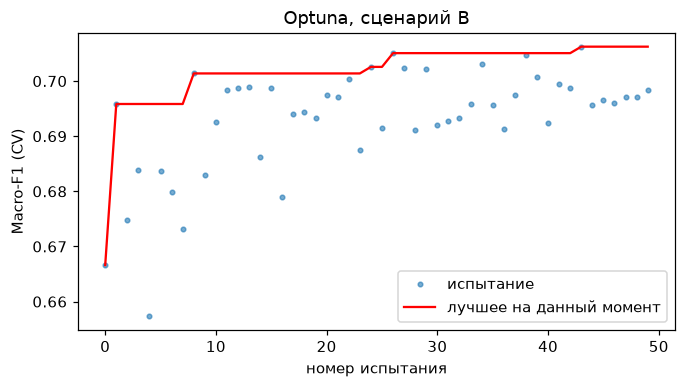

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.5))
vals = [t.value for t in study_B.trials]
ax.plot(vals, 'o', ms=3, alpha=0.6, label='испытание')
ax.plot(np.maximum.accumulate(vals), 'r-', label='лучшее на данный момент')
ax.set_xlabel('номер испытания'); ax.set_ylabel('Macro-F1 (CV)'); ax.legend(); ax.set_title('Optuna, сценарий B')
plt.savefig('figures/optuna.png'); plt.show()

In [19]:
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score

def to_cb(X):
    X = X.copy()
    for c in X.select_dtypes('category').columns:   # CatBoost: категории строками без NaN
        X[c] = X[c].astype(object).fillna('missing').astype(str)
    return X

def catboost_scenario(Xtr, scenario):
    Xc = to_cb(Xtr)
    cat_cols = Xc.select_dtypes(exclude='number').columns.tolist()
    X_tr, X_val, y_tr, y_val = train_test_split(Xc, y_train, test_size=0.2, stratify=y_train,
                                                random_state=RANDOM_STATE)
    cb = CatBoostClassifier(iterations=3000, learning_rate=0.05, loss_function='MultiClass',
                            eval_metric='TotalF1:average=Macro', early_stopping_rounds=200,
                            random_seed=RANDOM_STATE, verbose=0, thread_count=-1)
    cb.fit(X_tr, y_tr, cat_features=cat_cols, eval_set=(X_val, y_val))
    params = {'iterations': max(cb.get_best_iteration(), 50), 'learning_rate': 0.05,
              'loss_function': 'MultiClass', 'random_seed': RANDOM_STATE, 'verbose': 0}
    # CatBoost не клонируется sklearn с cat_features в конструкторе, поэтому CV — вручную
    s = []
    for tr_i, va_i in cv.split(Xc, y_train):
        m = CatBoostClassifier(**params).fit(Xc.iloc[tr_i], y_train.iloc[tr_i], cat_features=cat_cols)
        s.append(f1_score(y_train.iloc[va_i], m.predict(Xc.iloc[va_i]).ravel().astype(int), average='macro'))
    s = np.array(s)
    log_experiment('catboost', scenario, params, s)
    cv_table.append({'Сценарий': scenario, 'Модель': 'catboost', 'Macro-F1 CV': s.mean(), 'std': s.std()})
    print(f'{scenario}: best_iter = {cb.get_best_iteration()}, Macro-F1 CV = {s.mean():.4f} ± {s.std():.4f}')
    return params, cat_cols

cb_params_B, cat_cols_B = catboost_scenario(X_train_B, 'B: после 1-го семестра')
cb_params_A, cat_cols_A = catboost_scenario(X_train_A, 'A: при зачислении')

B: после 1-го семестра: best_iter = 587, Macro-F1 CV = 0.6657 ± 0.0145


A: при зачислении: best_iter = 954, Macro-F1 CV = 0.5112 ± 0.0076


In [20]:
# логистическая регрессия на итоговых наборах признаков (baseline для сравнения на тесте)
run_cv('logreg (итоговые признаки)', 'B: после 1-го семестра', logreg(COLS_B), COLS_B)
run_cv('logreg (итоговые признаки)', 'A: при зачислении', logreg(COLS_A), COLS_A)
cv_df = pd.DataFrame(cv_table)
cv_df.round(4)

B: после 1-го семестра       logreg (итоговые признаки)   0.6660 ± 0.0191


A: при зачислении            logreg (итоговые признаки)   0.5116 ± 0.0109


,Сценарий,Модель,Macro-F1 CV,std
0,A: при зачислении,dummy (prior),0.2220,0.0002
1,A: при зачислении,logreg,0.5116,0.0109
2,A: при зачислении,lightgbm default,0.5246,0.0140
3,B: после 1-го семестра,dummy (prior),0.2220,0.0002
4,B: после 1-го семестра,logreg,0.6646,0.0102
5,B: после 1-го семестра,lightgbm default,0.6760,0.0216
6,контроль,logreg + 2-й семестр (утечка),0.6988,0.0208
7,B: после 1-го семестра,lightgbm optuna,0.7062,0.0131
8,A: при зачислении,lightgbm optuna,0.5578,0.0170
9,B: после 1-го семестра,catboost,0.6657,0.0145


## Шаг 6. Итоговая оценка на тестовой выборке (один раз)

In [21]:
from sklearn.metrics import f1_score, accuracy_score, brier_score_loss, classification_report

def macro_f1(y, p): return f1_score(y, p, average='macro')

# сценарий B — основной
lgb_B = lgb.LGBMClassifier(**best_B).fit(X_train_B, y_train)
cb_B = CatBoostClassifier(**cb_params_B, cat_features=cat_cols_B).fit(to_cb(X_train_B), y_train)
lr_B = make_pipeline(linear_preprocess(), LogisticRegression(max_iter=3000)).fit(X_train_B, y_train)
# сценарий A
lgb_A = lgb.LGBMClassifier(**best_A).fit(X_train_A, y_train)
cb_A = CatBoostClassifier(**cb_params_A, cat_features=cat_cols_A).fit(to_cb(X_train_A), y_train)
lr_A = make_pipeline(linear_preprocess(), LogisticRegression(max_iter=3000)).fit(X_train_A, y_train)
dummy = DummyClassifier(strategy='prior').fit(X_train_B, y_train)

preds, probas = {}, {}
for key, m, Xt in [('B lightgbm', lgb_B, X_test_B), ('B catboost', cb_B, to_cb(X_test_B)), ('B logreg', lr_B, X_test_B),
                   ('A lightgbm', lgb_A, X_test_A), ('A catboost', cb_A, to_cb(X_test_A)), ('A logreg', lr_A, X_test_A),
                   ('dummy', dummy, X_test_B)]:
    probas[key] = m.predict_proba(Xt)
    preds[key] = probas[key].argmax(1)

test_rows = []
for k in preds:
    test_rows.append({'Модель': k, 'Macro-F1': macro_f1(y_test, preds[k]),
                      'Accuracy': accuracy_score(y_test, preds[k]),
                      'ROC-AUC Dropout': roc_auc_score(y_test == 0, probas[k][:, 0])})
test_df = pd.DataFrame(test_rows)
test_df.round(4)

,Модель,Macro-F1,Accuracy,ROC-AUC Dropout
0,B lightgbm,0.6630,0.7085,0.8945
1,B catboost,0.6538,0.7446,0.9032
2,B logreg,0.6770,0.7525,0.9024
3,A lightgbm,0.5396,0.5729,0.7701
4,A catboost,0.4840,0.5944,0.7728
5,A logreg,0.4837,0.5977,0.7711
6,dummy,0.2221,0.4994,0.5000


In [22]:
def bootstrap_diff(y_true, score_a, score_b, metric, n_boot=1000):
    # интервалы метрики модели A и разности A − B на одних бутстреп-выборках
    rng = np.random.default_rng(RANDOM_STATE)
    y_true = np.asarray(y_true)
    score_a, score_b = np.asarray(score_a), np.asarray(score_b)
    a_vals, diffs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:   # в выборку попал один класс
            continue
        a = metric(y_true[idx], score_a[idx])
        a_vals.append(a)
        diffs.append(a - metric(y_true[idx], score_b[idx]))
    return (np.percentile(a_vals, [2.5, 97.5]), np.percentile(diffs, [2.5, 97.5]))

ci_rows = []
for a, b in [('B lightgbm', 'B logreg'), ('B lightgbm', 'B catboost'), ('B lightgbm', 'A lightgbm'),
             ('B lightgbm', 'dummy'), ('A lightgbm', 'A logreg'), ('A catboost', 'A lightgbm')]:
    ci_a, ci_d = bootstrap_diff(y_test, preds[a], preds[b], macro_f1)
    ci_rows.append({'A': a, 'B': b, 'Macro-F1 A': macro_f1(y_test, preds[a]),
                    'ДИ A': f'[{ci_a[0]:.3f}; {ci_a[1]:.3f}]', 'ДИ разности A−B': f'[{ci_d[0]:+.3f}; {ci_d[1]:+.3f}]',
                    'значимо': not (ci_d[0] <= 0 <= ci_d[1])})
ci_df = pd.DataFrame(ci_rows)
ci_df

,A,B,Macro-F1 A,ДИ A,ДИ разности A−B,значимо
0,B lightgbm,B logreg,0.663013,[0.627; 0.695],[-0.045; +0.018],False
1,B lightgbm,B catboost,0.663013,[0.627; 0.695],[-0.022; +0.042],False
2,B lightgbm,A lightgbm,0.663013,[0.627; 0.695],[+0.087; +0.159],True
3,B lightgbm,dummy,0.663013,[0.627; 0.695],[+0.403; +0.475],True
4,A lightgbm,A logreg,0.539586,[0.506; 0.573],[+0.025; +0.089],True
5,A catboost,A lightgbm,0.483951,[0.450; 0.518],[-0.094; -0.019],True


In [23]:
print(classification_report(y_test, preds['B lightgbm'], target_names=CLASSES, digits=3))

              precision    recall  f1-score   support

     Dropout      0.780     0.676     0.725       284
    Enrolled      0.391     0.541     0.454       159
    Graduate      0.833     0.790     0.811       442

    accuracy                          0.708       885
   macro avg      0.668     0.669     0.663       885
weighted avg      0.737     0.708     0.719       885



## Шаг 7. Калибровка и выбор порога для класса Dropout

In [24]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay

y_tr_d = (y_train == 0).astype(int).values
y_te_d = (y_test == 0).astype(int).values

# out-of-fold вероятности: сырая модель и две калибровки
oof = {'raw': cross_val_predict(lgb.LGBMClassifier(**best_B), X_train_B, y_train, cv=cv, method='predict_proba')}
for method in ['sigmoid', 'isotonic']:
    oof[method] = cross_val_predict(CalibratedClassifierCV(lgb.LGBMClassifier(**best_B), method=method, cv=5),
                                    X_train_B, y_train, cv=cv, method='predict_proba')
brier_oof = {k: brier_score_loss(y_tr_d, v[:, 0]) for k, v in oof.items()}
print('Brier (OOF, Dropout):', {k: round(v, 4) for k, v in brier_oof.items()})
cal_method = min(['sigmoid', 'isotonic'], key=lambda m: brier_oof[m])
print('выбран метод калибровки:', cal_method)

Brier (OOF, Dropout): {'raw': 0.1021, 'sigmoid': 0.1026, 'isotonic': 0.1024}
выбран метод калибровки: isotonic


Brier на тесте: сырая 0.1121, откалиброванная 0.1099
ROC-AUC Dropout: сырая 0.8945, откалиброванная 0.8957


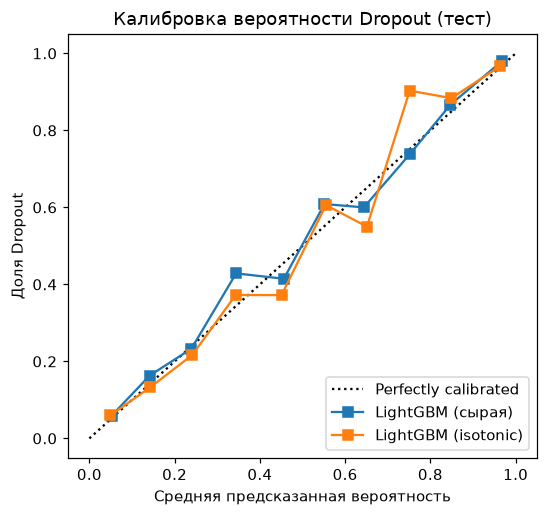

In [25]:
calibrated_B = CalibratedClassifierCV(lgb.LGBMClassifier(**best_B), method=cal_method, cv=5).fit(X_train_B, y_train)
p_raw_te = probas['B lightgbm'][:, 0]
p_cal_te = calibrated_B.predict_proba(X_test_B)[:, 0]
print(f'Brier на тесте: сырая {brier_score_loss(y_te_d, p_raw_te):.4f}, откалиброванная {brier_score_loss(y_te_d, p_cal_te):.4f}')
print(f'ROC-AUC Dropout: сырая {roc_auc_score(y_te_d, p_raw_te):.4f}, откалиброванная {roc_auc_score(y_te_d, p_cal_te):.4f}')

fig, ax = plt.subplots(figsize=(5.5, 5))
CalibrationDisplay.from_predictions(y_te_d, p_raw_te, n_bins=10, name='LightGBM (сырая)', ax=ax)
CalibrationDisplay.from_predictions(y_te_d, p_cal_te, n_bins=10, name=f'LightGBM ({cal_method})', ax=ax)
ax.set_title('Калибровка вероятности Dropout (тест)')
ax.set_xlabel('Средняя предсказанная вероятность'); ax.set_ylabel('Доля Dropout')
plt.savefig('figures/calibration.png'); plt.show()

In [26]:
def total_cost(y_true, proba, t, c_fn=C_FN, c_fp=C_FP):
    y_true, pred = np.asarray(y_true), np.asarray(proba) >= t
    fn = np.sum(~pred & (y_true == 1))
    fp = np.sum(pred & (y_true == 0))
    return c_fn * fn + c_fp * fp

grid = np.round(np.linspace(0.01, 0.99, 99), 2)
p_oof_B = oof[cal_method][:, 0]
costs_oof = [total_cost(y_tr_d, p_oof_B, t) for t in grid]
t_best = float(grid[int(np.argmin(costs_oof))])
t_theory = C_FP / (C_FP + C_FN)
print(f'порог по данным (OOF): {t_best:.2f}, теоретический t* = {t_theory:.3f}')

# сценарий A: тот же подход
cal_A = CalibratedClassifierCV(lgb.LGBMClassifier(**best_A), method=cal_method, cv=5)
p_oof_A = cross_val_predict(cal_A, X_train_A, y_train, cv=cv, method='predict_proba')[:, 0]
t_best_A = float(grid[int(np.argmin([total_cost(y_tr_d, p_oof_A, t) for t in grid]))])
cal_A.fit(X_train_A, y_train)
p_cal_te_A = cal_A.predict_proba(X_test_A)[:, 0]
print(f'сценарий A: порог {t_best_A:.2f}, Brier тест {brier_score_loss(y_te_d, p_cal_te_A):.4f}, '
      f'ROC-AUC {roc_auc_score(y_te_d, p_cal_te_A):.4f}')

порог по данным (OOF): 0.12, теоретический t* = 0.091


сценарий A: порог 0.08, Brier тест 0.1753, ROC-AUC 0.7670


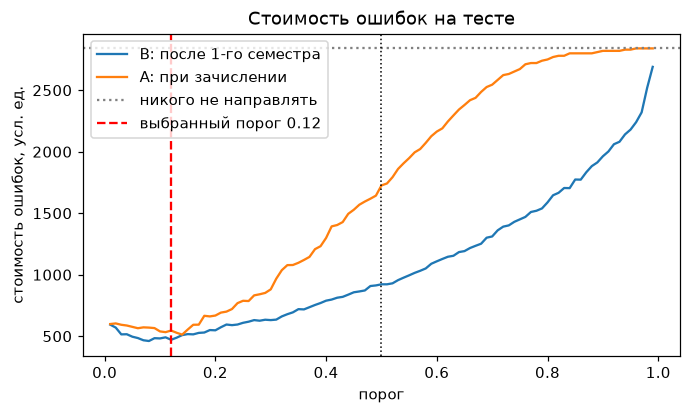

In [27]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, [total_cost(y_te_d, p_cal_te, t) for t in grid], label='B: после 1-го семестра')
ax.plot(grid, [total_cost(y_te_d, p_cal_te_A, t) for t in grid], label='A: при зачислении')
ax.axhline(C_FN * y_te_d.sum(), color='gray', ls=':', label='никого не направлять')
ax.axvline(t_best, color='r', ls='--', label=f'выбранный порог {t_best:.2f}')
ax.axvline(0.5, color='k', ls=':', lw=1)
ax.set_xlabel('порог'); ax.set_ylabel('стоимость ошибок, усл. ед.'); ax.legend(); ax.set_title('Стоимость ошибок на тесте')
plt.savefig('figures/cost_threshold.png'); plt.show()

In [28]:
from sklearn.metrics import confusion_matrix

def strategy(name, y, sel):
    sel = np.asarray(sel, bool)
    tp = int(np.sum(sel & (y == 1))); fp = int(np.sum(sel & (y == 0)))
    fn = int(np.sum(~sel & (y == 1))); tn = int(np.sum(~sel & (y == 0)))
    return {'Стратегия': name, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Precision': tp / (tp + fp) if tp + fp else np.nan, 'Recall': tp / (tp + fn),
            'Доля направленных': sel.mean(), 'Стоимость': C_FN * fn + C_FP * fp}

strat = pd.DataFrame([
    strategy('Никого не направлять', y_te_d, np.zeros_like(y_te_d)),
    strategy('Направлять всех', y_te_d, np.ones_like(y_te_d)),
    strategy('B: argmax по 3 классам', y_te_d, preds['B lightgbm'] == 0),
    strategy('B: порог 0,50', y_te_d, p_cal_te >= 0.5),
    strategy(f'B: порог {t_best:.2f} (по стоимости)', y_te_d, p_cal_te >= t_best),
    strategy(f'A: порог {t_best_A:.2f} (при зачислении)', y_te_d, p_cal_te_A >= t_best_A),
])
strat.round(3)

,Стратегия,TP,FP,FN,TN,Precision,Recall,Доля направленных,Стоимость
0,Никого не направлять,0,0,284,601,NaN,0.000,0.000,2840.0
1,Направлять всех,284,601,0,0,0.321,1.000,1.000,601.0
2,B: argmax по 3 классам,192,54,92,547,0.780,0.676,0.278,974.0
3,"B: порог 0,50",196,42,88,559,0.824,0.690,0.269,922.0
4,B: порог 0.12 (по стоимости),260,231,24,370,0.530,0.915,0.555,471.0
5,A: порог 0.08 (при зачислении),279,520,5,81,0.349,0.982,0.903,570.0


## Шаг 8. Интерпретация (SHAP)

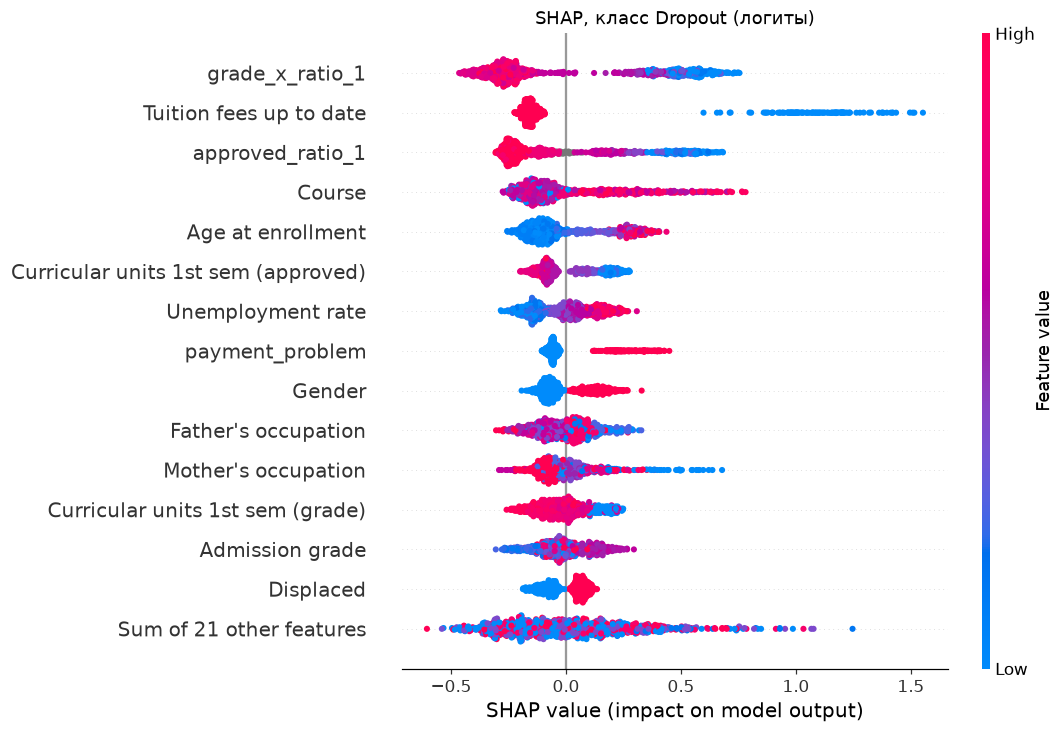

In [29]:
# точные TreeSHAP-вклады средствами LightGBM: форма (n, 3 * (k + 1)), в логитах
X_expl = X_test_B.sample(min(2000, len(X_test_B)), random_state=RANDOM_STATE)
contrib = lgb_B.predict(X_expl, pred_contrib=True)
k = X_expl.shape[1]
contrib = contrib.reshape(len(X_expl), 3, k + 1)
X_disp = X_expl.copy()
for c in X_disp.select_dtypes('category').columns:
    X_disp[c] = X_disp[c].astype(float)
sv = shap.Explanation(values=contrib[:, 0, :k], base_values=contrib[:, 0, k],
                      data=X_disp.values, feature_names=list(X_expl.columns))   # класс Dropout
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('SHAP, класс Dropout (логиты)')
plt.savefig('figures/shap_beeswarm.png'); plt.show()

In [30]:
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=X_expl.columns)
mean_abs_all = pd.Series(np.abs(contrib[:, :, :k]).mean(0).sum(0), index=X_expl.columns)
gain = pd.Series(lgb_B.booster_.feature_importance('gain'), index=X_expl.columns)
imp = pd.DataFrame({'mean|SHAP| Dropout': mean_abs, 'mean|SHAP| все классы': mean_abs_all, 'gain': gain})
imp['ранг SHAP Dropout'] = imp['mean|SHAP| Dropout'].rank(ascending=False).astype(int)
imp['ранг SHAP все'] = imp['mean|SHAP| все классы'].rank(ascending=False).astype(int)
imp['ранг gain'] = imp['gain'].rank(ascending=False).astype(int)
imp = imp.sort_values('ранг SHAP Dropout')
imp.head(12).round(3)

,mean|SHAP| Dropout,mean|SHAP| все классы,gain,ранг SHAP Dropout,ранг SHAP все,ранг gain
grade_x_ratio_1,0.344,0.850,11425.243,1,2,1
Tuition fees up to date,0.273,0.460,3481.892,2,4,5
approved_ratio_1,0.252,0.926,7944.651,3,1,2
Course,0.171,0.529,4028.323,4,3,4
Age at enrollment,0.150,0.317,2362.541,5,6,9
Curricular units 1st sem (approved),0.115,0.251,3008.680,6,12,8
Unemployment rate,0.109,0.223,1458.869,7,13,16
payment_problem,0.101,0.251,1689.392,8,11,15
Gender,0.095,0.171,731.048,9,17,23
Father's occupation,0.094,0.261,1834.732,10,9,13


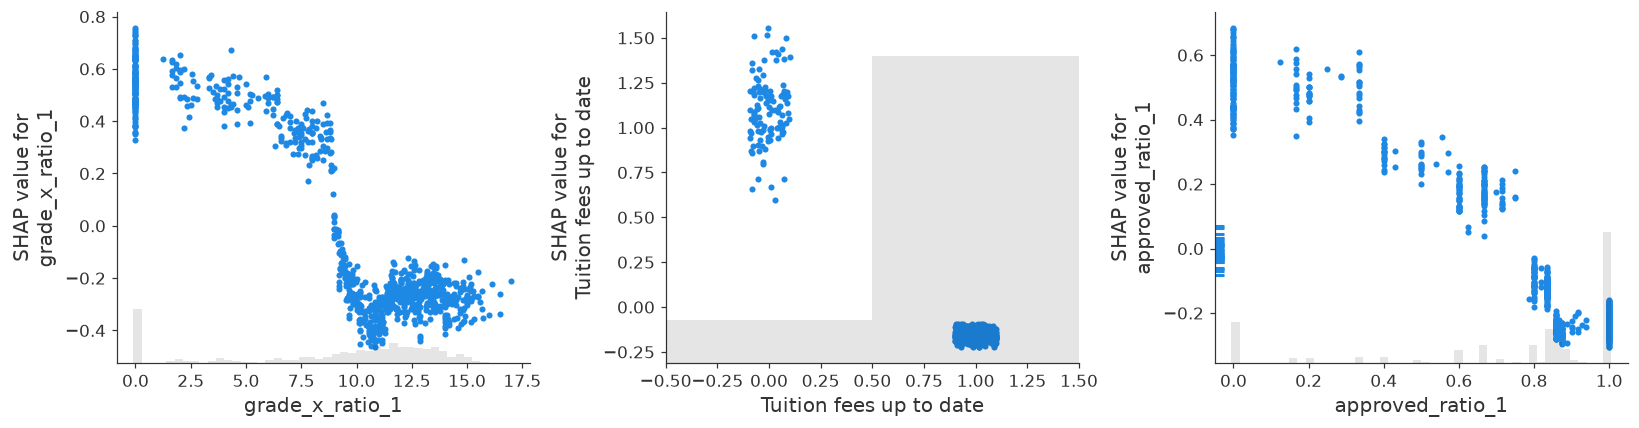

['grade_x_ratio_1', 'Tuition fees up to date', 'approved_ratio_1']


In [31]:
top3 = mean_abs.sort_values(ascending=False).index[:3].tolist()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, top3):
    shap.plots.scatter(sv[:, f], ax=ax, show=False)
plt.tight_layout(); plt.savefig('figures/shap_scatter.png'); plt.show()
print(top3)

верное срабатывание (TP): индекс 1572, p(Dropout) = 1.000, факт = Dropout


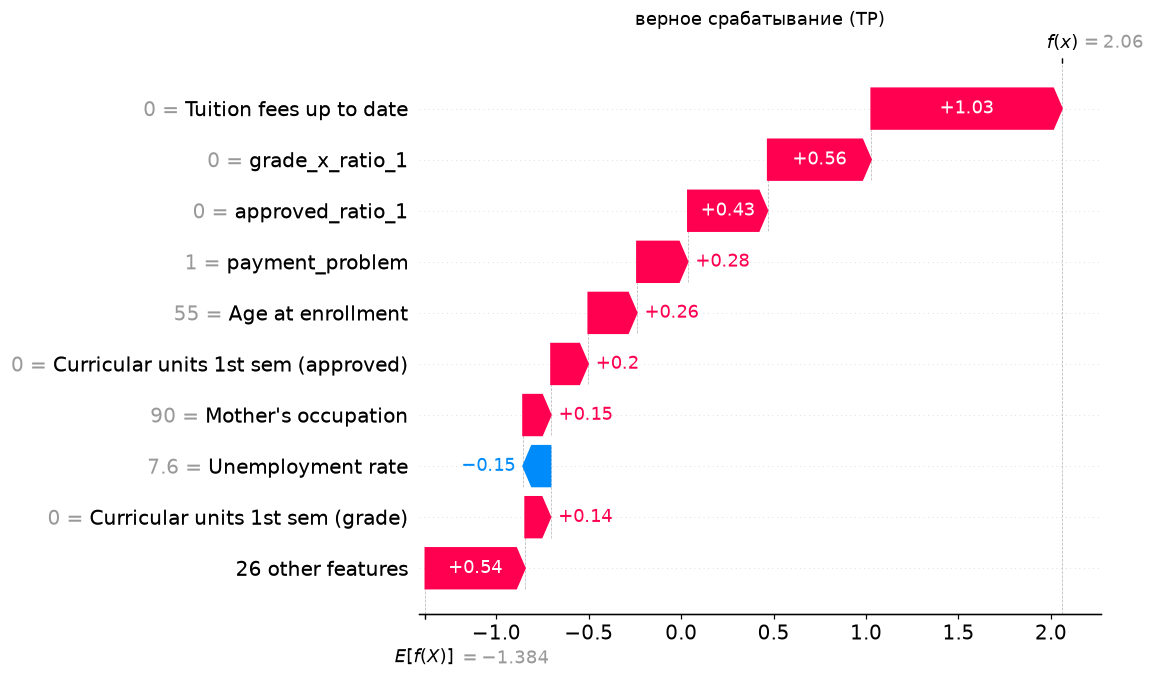

ложная тревога (FP): индекс 942, p(Dropout) = 0.940, факт = Enrolled


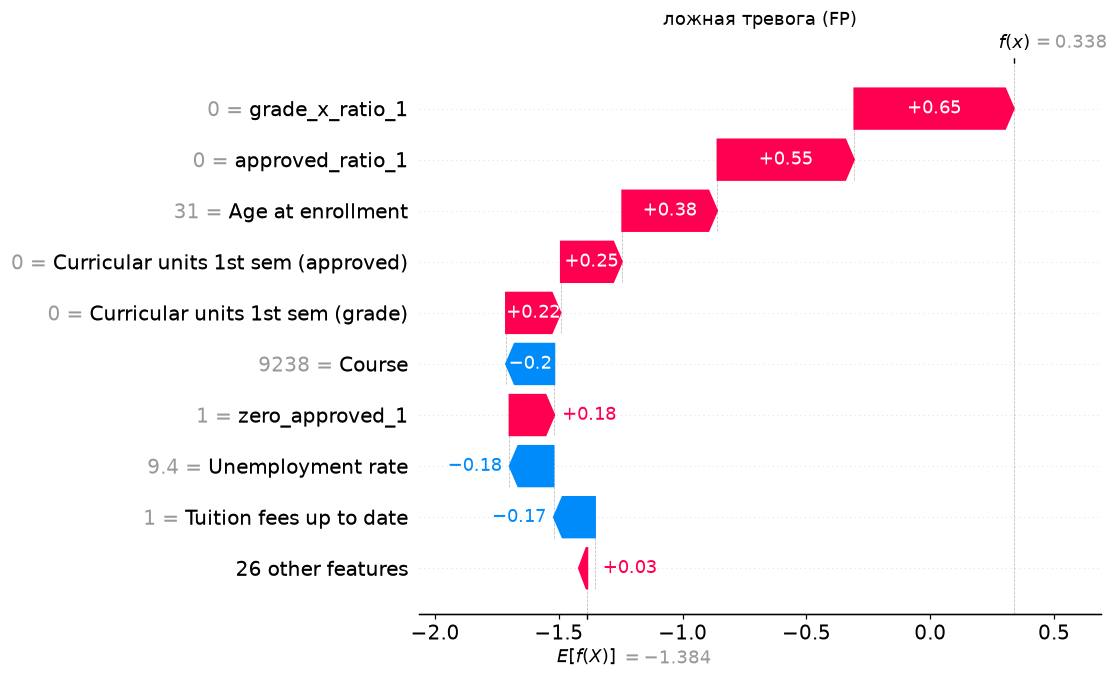

пропуск (FN): индекс 2126, p(Dropout) = 0.019, факт = Dropout


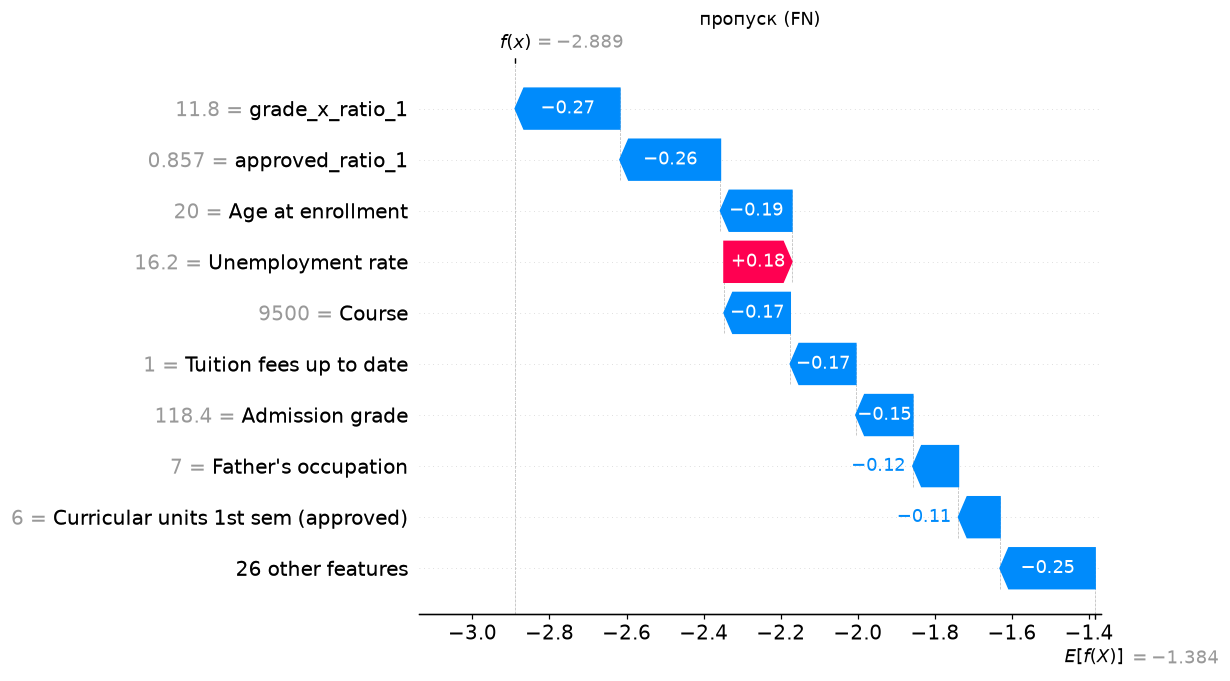

In [32]:
sel_te = p_cal_te >= t_best
pos = {X_test_B.index[i]: i for i in range(len(X_test_B))}
expl_idx = list(X_expl.index)
def pick(mask):
    cand = [ix for ix in X_test_B.index[mask] if ix in set(expl_idx)]
    # самый «уверенный» случай по калиброванной вероятности
    return max(cand, key=lambda ix: abs(p_cal_te[pos[ix]] - t_best)) if cand else None
cases = {'верное срабатывание (TP)': pick(sel_te & (y_te_d == 1)),
         'ложная тревога (FP)': pick(sel_te & (y_te_d == 0)),
         'пропуск (FN)': pick(~sel_te & (y_te_d == 1))}
for i, (name, ix) in enumerate(cases.items()):
    j = expl_idx.index(ix)
    print(f'{name}: индекс {ix}, p(Dropout) = {p_cal_te[pos[ix]]:.3f}, факт = {CLASSES[y_test.loc[ix]]}')
    plt.figure()
    shap.plots.waterfall(sv[j], max_display=10, show=False)
    plt.title(name)
    plt.savefig(f'figures/shap_waterfall_{i + 1}.png'); plt.show()

## Дополнительное задание: справедливость модели
Чувствительные признаки: пол (Gender: 1 — мужской, 0 — женский), возраст при зачислении, гражданство (International). Сравниваем долю направленных к куратору и recall по группам при выбранном пороге, а затем модель без чувствительных признаков.

In [33]:
def group_report(groups, sel, y):
    rows = []
    for g in pd.unique(groups):
        m = groups == g
        rows.append({'группа': g, 'n': int(m.sum()), 'доля Dropout': y[m].mean(),
                     'доля направленных': sel[m].mean(),
                     'recall': sel[m & (y == 1)].mean() if (m & (y == 1)).any() else np.nan,
                     'precision': y[m & sel].mean() if (m & sel).any() else np.nan})
    return pd.DataFrame(rows).sort_values('группа')

age_grp = pd.cut(X_test['Age at enrollment'], [0, 20, 25, 100], labels=['≤20', '21–25', '>25']).astype(str).values
fair = {'Пол': np.where(X_test['Gender'].values == 1, 'мужской', 'женский'),
        'Возраст': age_grp,
        'Гражданство': np.where(X_test['International'].values == 1, 'иностранец', 'гражданин')}
for name, g in fair.items():
    print(name); print(group_report(g, sel_te, y_te_d).round(3).to_string(index=False)); print()

Пол
 группа   n  доля Dropout  доля направленных  recall  precision
женский 570         0.244              0.470   0.885      0.459
мужской 315         0.460              0.708   0.945      0.614

Возраст
группа   n  доля Dropout  доля направленных  recall  precision
 21–25 180         0.322              0.600   0.914      0.491
   >25 215         0.553              0.753   0.941      0.691
   ≤20 490         0.218              0.451   0.888      0.430

Гражданство
    группа   n  доля Dropout  доля направленных  recall  precision
 гражданин 861         0.319              0.553   0.916      0.529
иностранец  24         0.375              0.625   0.889      0.533



In [34]:
SENSITIVE = ['Gender', 'Age at enrollment', 'Nacionality', 'International', 'mature_student']
COLS_FAIR = [c for c in COLS_B if c not in SENSITIVE]
Xf_tr, Xf_te = prepare(X_train, COLS_FAIR), prepare(X_test, COLS_FAIR)
s_fair = cross_val_score(lgb.LGBMClassifier(**best_B), Xf_tr, y_train, cv=cv, scoring='f1_macro')
log_experiment('lightgbm optuna', 'B без чувствительных', best_B, s_fair)
cal_fair = CalibratedClassifierCV(lgb.LGBMClassifier(**best_B), method=cal_method, cv=5)
p_oof_f = cross_val_predict(cal_fair, Xf_tr, y_train, cv=cv, method='predict_proba')[:, 0]
t_fair = float(grid[int(np.argmin([total_cost(y_tr_d, p_oof_f, t) for t in grid]))])
cal_fair.fit(Xf_tr, y_train)
p_fair_te = cal_fair.predict_proba(Xf_te)[:, 0]
sel_fair = p_fair_te >= t_fair
lgb_fair = lgb.LGBMClassifier(**best_B).fit(Xf_tr, y_train)
print(f'Без чувствительных признаков: Macro-F1 CV {s_fair.mean():.4f} ± {s_fair.std():.4f}, '
      f'тест {macro_f1(y_test, lgb_fair.predict(Xf_te)):.4f}, ROC-AUC Dropout {roc_auc_score(y_te_d, p_fair_te):.4f}, '
      f'порог {t_fair:.2f}, стоимость {total_cost(y_te_d, p_fair_te, t_fair):.0f} '
      f'(с ними: {total_cost(y_te_d, p_cal_te, t_best):.0f})')
for name, g in fair.items():
    print(name); print(group_report(g, sel_fair, y_te_d).round(3).to_string(index=False)); print()

Без чувствительных признаков: Macro-F1 CV 0.6995 ± 0.0142, тест 0.6693, ROC-AUC Dropout 0.8902, порог 0.07, стоимость 508 (с ними: 471)
Пол
 группа   n  доля Dropout  доля направленных  recall  precision
женский 570         0.244              0.672   0.935      0.339
мужской 315         0.460              0.775   0.959      0.570

Возраст
группа   n  доля Dropout  доля направленных  recall  precision
 21–25 180         0.322              0.744   0.914      0.396
   >25 215         0.553              0.833   0.975      0.648
   ≤20 490         0.218              0.641   0.935      0.318

Гражданство
    группа   n  доля Dropout  доля направленных  recall  precision
 гражданин 861         0.319              0.704   0.945      0.429
иностранец  24         0.375              0.875   1.000      0.429



## Шаг 9. Сохранение модели

In [35]:
import joblib
final_pipeline = make_pipeline(
    FunctionTransformer(prepare, kw_args={'cols': COLS_B}),
    CalibratedClassifierCV(lgb.LGBMClassifier(**best_B), method=cal_method, cv=5))
final_pipeline.fit(X_train[RAW_B], y_train)
joblib.dump({'pipeline': final_pipeline, 'threshold': t_best, 'classes': CLASSES, 'positive_class': 'Dropout',
             'scenario': 'после 1-го семестра', 'input_columns': RAW_B, 'features': COLS_B},
            'model.joblib')

def column_schema(s):
    if s.name in NOMINAL:
        return {'type': 'category', 'values': sorted(int(v) for v in s.dropna().unique())}
    if pd.api.types.is_numeric_dtype(s):
        return {'type': 'number', 'min': float(s.min()), 'max': float(s.max())}
    return {'type': 'category', 'values': sorted(s.dropna().astype(str).unique().tolist())}

schema = {col: column_schema(X_train[col]) for col in RAW_B}
with open('input_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

bundle = joblib.load('model.joblib')
assert np.allclose(bundle['pipeline'].predict_proba(X_test[RAW_B]), final_pipeline.predict_proba(X_test[RAW_B]))
p_final = bundle['pipeline'].predict_proba(X_test[RAW_B])[:, 0]
print('Проверка загрузки пройдена; размер model.joblib:', round(os.path.getsize('model.joblib') / 1024, 1), 'КБ')
print('Стоимость финального пайплайна на тесте:', total_cost(y_te_d, p_final, bundle['threshold']))
print('Признаков во входной схеме:', len(schema), '| записей в experiments.csv:', len(pd.read_csv('experiments.csv')))

Проверка загрузки пройдена; размер model.joblib: 7155.1 КБ
Стоимость финального пайплайна на тесте: 471.0
Признаков во входной схеме: 30 | записей в experiments.csv: 120


In [36]:
# сводка результатов для отчёта
summary = {
    'n_rows': len(df), 'class_counts': df['Target'].value_counts().to_dict(),
    'leak_top': leak.head(12).round(4).to_dict(),
    'ablation': ablation.round(4).to_dict('records'), 'keep_new': keep_new, 'drop_new': drop_new,
    'abl_full': [float(full.mean()), float(full.std())], 'abl_base': [float(base.mean()), float(base.std())],
    'cv': cv_df.round(4).to_dict('records'), 'test': test_df.round(4).to_dict('records'),
    'ci': ci_df.to_dict('records'), 'best_B': best_B, 'best_A': best_A,
    'cb_iter_B': cb_params_B['iterations'], 'cb_iter_A': cb_params_A['iterations'],
    'brier_oof': brier_oof, 'cal_method': cal_method,
    'brier_test': [brier_score_loss(y_te_d, p_raw_te), brier_score_loss(y_te_d, p_cal_te)],
    't_best': t_best, 't_best_A': t_best_A, 'strategies': strat.round(4).to_dict('records'),
    'importance': imp.head(12).round(4).reset_index().to_dict('records'), 'top3': top3,
    'cases': {k: [int(v), float(p_cal_te[pos[v]]), CLASSES[y_test.loc[v]]] for k, v in cases.items()},
    'n_features_A': len(COLS_A), 'n_features_B': len(COLS_B),
    'report_B': classification_report(y_test, preds['B lightgbm'], target_names=CLASSES, output_dict=True),
}
with open('results_summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=1, default=float)
print('готово')

готово
